# 04 · Does Missing the Delivery Promise Cost Stars?

**Hypothesis H3** (from `docs/review_analysis/01_problem_statement.md`):
*Missing the promised delivery date lowers the rating sharply, regardless of total delivery time.*

This notebook tests H3 with **structured data only**, before any AI is used.
It also measures how much of the 1–2 star problem delivery data can explain on its own,
and how much is left for the review texts to explain.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
})

## 1. Data
One review per order (the latest answer), joined with the order's purchase, delivery and promised dates.

In [2]:
orders = pd.read_csv("../data/olist_orders_dataset.csv", parse_dates=[
    "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"])
reviews = (pd.read_csv("../data/olist_order_reviews_dataset.csv")
           .sort_values("review_answer_timestamp")
           .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])

df = orders.merge(reviews, on="order_id", how="inner")
df["negative"] = df["review_score"] <= 2
df["delivered"] = df["order_delivered_customer_date"].notna()
df["delivery_days"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.days
df["delay_days"] = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.days
df["late"] = df["delay_days"] > 0

delivered = df[df["delivered"]].copy()
print(f"Orders with a review: {len(df):,} | delivered: {len(delivered):,} | not delivered: {(~df['delivered']).sum():,}")

Orders with a review: 98,673 | delivered: 95,830 | not delivered: 2,843


## 2. Late vs on time

In [3]:
summary = delivered.groupby("late").agg(
    orders=("order_id", "count"),
    avg_score=("review_score", "mean"),
    negative_share=("negative", "mean"),
).rename(index={False: "On time", True: "Late"})
summary["share_of_orders"] = summary["orders"] / summary["orders"].sum()

chi2, p, _, _ = chi2_contingency(pd.crosstab(delivered["late"], delivered["negative"]))
print("Chi-square test (late vs negative): " + ("p < 1e-300" if p == 0 else f"p = {p:.1e}"))
summary.style.format({"avg_score": "{:.2f}", "negative_share": "{:.1%}", "share_of_orders": "{:.1%}", "orders": "{:,}"})

Chi-square test (late vs negative): p < 1e-300


,orders,avg_score,negative_share,share_of_orders
late,,,,
On time,"89,448",4.29,9.3%,93.3%
Late,"6,382",2.27,62.4%,6.7%


## 3. How late is too late?
Share of 1–2 star reviews by how early or late the order arrived compared with the promised date.

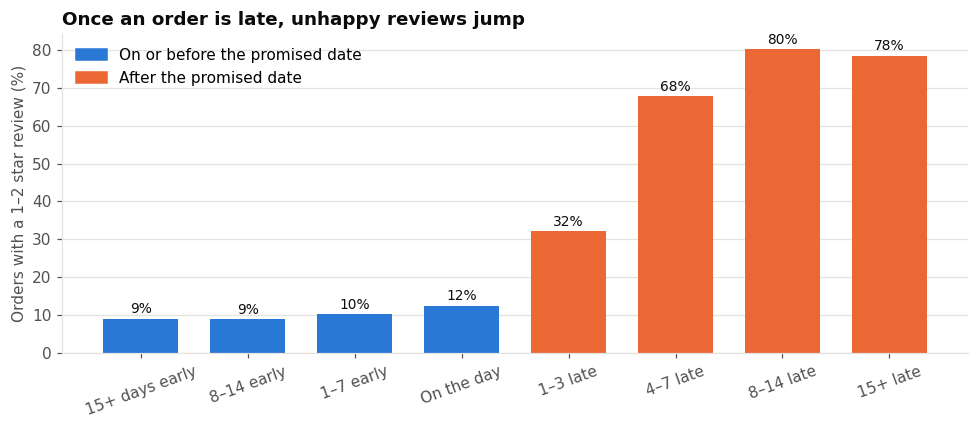

,orders,negative_share
delay_bucket,,
15+ days early,"34,776",9.1%
8–14 early,"36,158",8.9%
1–7 early,"17,234",10.2%
On the day,"1,280",12.4%
1–3 late,"1,852",32.1%
4–7 late,"1,748",67.7%
8–14 late,"1,447",80.1%
15+ late,"1,335",78.4%


In [4]:
bins = [-1000, -15, -8, -1, 0, 3, 7, 14, 1000]
labels = ["15+ days early", "8–14 early", "1–7 early", "On the day", "1–3 late", "4–7 late", "8–14 late", "15+ late"]
delivered["delay_bucket"] = pd.cut(delivered["delay_days"], bins=bins, labels=labels)
by_delay = delivered.groupby("delay_bucket", observed=True).agg(
    orders=("order_id", "count"), negative_share=("negative", "mean"))

fig, ax = plt.subplots(figsize=(9, 4))
colors = [BLUE if not lab.endswith("late") else ORANGE for lab in by_delay.index]
bars = ax.bar(by_delay.index, by_delay["negative_share"] * 100, color=colors, width=0.7)
for bar, share in zip(bars, by_delay["negative_share"]):
    ax.text(bar.get_x() + bar.get_width() / 2, share * 100 + 1.5, f"{share:.0%}", ha="center", color=INK, fontsize=9)
ax.set_ylabel("Orders with a 1–2 star review (%)")
ax.set_title("Once an order is late, unhappy reviews jump", loc="left", color=INK, fontsize=12, fontweight="bold")
ax.legend(handles=[Patch(color=BLUE, label="On or before the promised date"), Patch(color=ORANGE, label="After the promised date")],
          frameon=False, loc="upper left")
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../outputs/06_delay_vs_negative_reviews.png", bbox_inches="tight")
plt.show()
by_delay.style.format({"negative_share": "{:.1%}", "orders": "{:,}"})

## 4. Is it the promise, or just slow delivery?
A late order is usually also a slow order. To separate the two, compare late and on-time orders
**with the same total delivery time**. If late orders are still rated much worse, the broken promise itself matters.

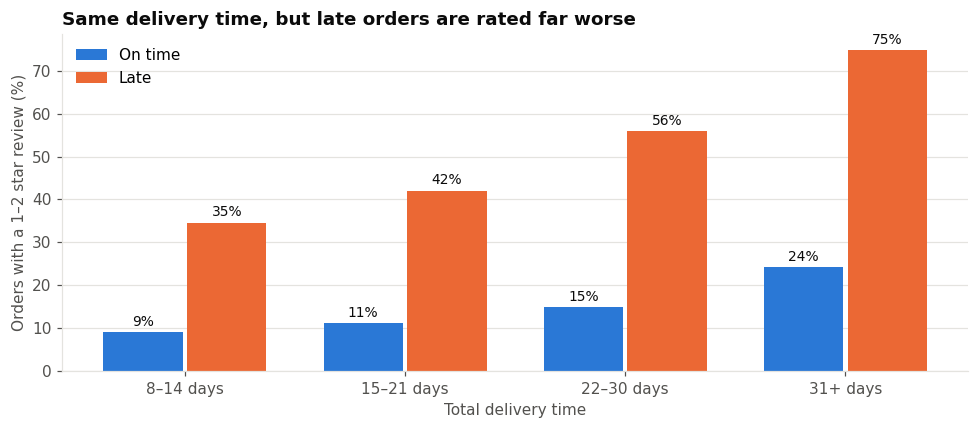

,neg_share_on_time,neg_share_late,orders_on_time,orders_late
speed,,,,
8–14 days,9.0%,34.6%,"35,850",341
15–21 days,11.2%,42.1%,"14,620",644
22–30 days,14.9%,55.9%,"4,776","2,050"
31+ days,24.3%,74.8%,754,"3,254"


In [5]:
speed_bins = [-1, 7, 14, 21, 30, 1000]
speed_labels = ["0–7 days", "8–14 days", "15–21 days", "22–30 days", "31+ days"]
delivered["speed"] = pd.cut(delivered["delivery_days"], bins=speed_bins, labels=speed_labels)
controlled = delivered.pivot_table(index="speed", columns="late", values="negative",
                                   aggfunc=["mean", "count"], observed=True)
controlled.columns = [f"{'neg_share' if a == 'mean' else 'orders'}_{'late' if b else 'on_time'}" for a, b in controlled.columns]
# Only compare groups with at least 100 orders on both sides (drops 0–7 days: almost none are late)
controlled = controlled[(controlled["orders_late"] >= 100) & (controlled["orders_on_time"] >= 100)]

fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(controlled))
w = 0.38
b1 = ax.bar([i - w / 2 for i in x], controlled["neg_share_on_time"] * 100, w - 0.02, color=BLUE, label="On time")
b2 = ax.bar([i + w / 2 for i in x], controlled["neg_share_late"] * 100, w - 0.02, color=ORANGE, label="Late")
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5, f"{bar.get_height():.0f}%",
                ha="center", color=INK, fontsize=9)
ax.set_xticks(list(x)); ax.set_xticklabels(controlled.index)
ax.set_xlabel("Total delivery time"); ax.set_ylabel("Orders with a 1–2 star review (%)")
ax.set_title("Same delivery time, but late orders are rated far worse", loc="left", color=INK, fontsize=12, fontweight="bold")
ax.legend(frameon=False, loc="upper left")
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("../outputs/07_promise_vs_speed.png", bbox_inches="tight")
plt.show()
controlled.style.format({c: "{:.1%}" if c.startswith("neg") else "{:,.0f}" for c in controlled.columns})

## 5. How much of the 1–2 star problem does delivery data explain?

In [6]:
neg = df[df["negative"]]
groups = pd.Series({
    "Never delivered": (~neg["delivered"]).sum(),
    "Delivered late": (neg["delivered"] & neg["late"]).sum(),
    "Delivered on time": (neg["delivered"] & ~neg["late"]).sum(),
})
share = groups / groups.sum()
print(f"All 1–2 star reviews: {groups.sum():,}")
print((share.map("{:.1%}".format) + "  (" + groups.map("{:,}".format) + ")").to_string())
print(f"\nNot delivered orders rated 1–2 stars: {df.loc[~df['delivered'], 'negative'].mean():.0%}")

All 1–2 star reviews: 14,494
Never delivered      15.3%  (2,218)
Delivered late       27.5%  (3,983)
Delivered on time    57.2%  (8,293)

Not delivered orders rated 1–2 stars: 78%


## Verdict on H3: **supported**

**1. Late orders are rated far worse.** Only 6.7% of delivered orders arrived late, but 62% of them got a 1–2 star review, compared with 9% of on-time orders. The average score falls from 4.29 to 2.27.

**2. The damage starts within days.** Arriving early or on the day keeps unhappy reviews around 9–12%. One to three days late already triples that to 32%; four to seven days late, 68%.

**3. It is the broken promise, not only the slow delivery.** At the same total delivery time, late orders get 3–4 times more 1–2 star reviews. For example, at 15–21 days: 11% if on time vs 42% if late. Setting realistic delivery estimates is a lever on its own, separate from delivering faster.

**4. Delivery data explains less than half of the problem.** Of all 14,494 1–2 star reviews:
- 15% are on orders that never arrived,
- 28% on orders that arrived late,
- **57% on orders that arrived on time.**

So H1 ("most complaints are about delivery") is not settled by these numbers. More than half of unhappy customers received their order on time. Why they are unhappy is only written in their reviews, and that is what the AI classification in the next phase will measure.

*Limitation:* this is an association. Late orders may also differ in other ways (region, category, seller), which the impact analysis (notebook 06) will break down.